# Travelling-Dirac paths

Reproduce the only-growth and only-death mass-path panels.

In [86]:
import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from utils import compute_uot_plans
import math


# Compute WFR semi-couplings between two snapshots.
def compute_exact_wfr_semi_coupling(X0, X1, delta, use_mini_batch=False, chunk_size=1024):


    _, gamma0s, gamma1s, _ = compute_uot_plans([X0, X1], [0, 1], delta, cuda=torch.cuda.is_available(), use_mini_batch_uot=use_mini_batch, chunk_size=chunk_size)

    Gamma1_exact = gamma0s[0]
    Gamma2_exact = gamma1s[0]
    return torch.from_numpy(Gamma1_exact), torch.from_numpy(Gamma2_exact)

# Parameterize the single-particle position and mass path.
class RUOT_TrajectoryNet(nn.Module):
    def __init__(self, hidden_dim=256):
        super().__init__()


        self.net = nn.Sequential(
            nn.Linear(3, hidden_dim),
            nn.SiLU(),
            nn.Linear(hidden_dim, hidden_dim),
            nn.SiLU(),
            nn.Linear(hidden_dim, hidden_dim),
            nn.SiLU(),
            nn.Linear(hidden_dim, hidden_dim),
            nn.SiLU(),
            nn.Linear(hidden_dim, 2)
        )

    def forward(self, d, m, t):


        log_m = torch.log(m + 1e-12)


        features = torch.stack([d, log_m, t], dim=-1)
        out = self.net(features)

        net_m = out[..., 0]
        net_x = out[..., 1]


        m_t = (m ** t) * torch.exp(t * (1 - t) * net_m)


        x_t = d * (t + t * (1 - t) * net_x)

        return m_t, x_t


import math

def compute_action_loss(model, Psi_func, batch_size, device):


    steps = int(math.sqrt(batch_size))


    d_axis = torch.linspace(0.1, 12, steps, device=device)
    m_axis = torch.logspace(-2, 2, steps, device=device)


    D_grid, M_grid = torch.meshgrid(d_axis, m_axis, indexing='ij')


    d = D_grid.reshape(-1)
    m = M_grid.reshape(-1)


    actual_batch = d.shape[0]


    t = torch.rand(actual_batch, device=device).requires_grad_(True)


    m_t, x_t = model(d, m, t)


    m_dot = torch.autograd.grad(
        outputs=m_t,
        inputs=t,
        grad_outputs=torch.ones_like(m_t),
        create_graph=True,
        retain_graph=True
    )[0]

    x_dot = torch.autograd.grad(
        outputs=x_t,
        inputs=t,
        grad_outputs=torch.ones_like(x_t),
        create_graph=True,
        retain_graph=True
    )[0]


    m_t_safe = torch.clamp(m_t, min=1e-6)

    kinetic_term = x_dot ** 2
    mass_penalty_term = Psi_func(m_dot / m_t_safe)

    action_density = 0.5 * (kinetic_term + mass_penalty_term) * m_t


    return action_density.mean()


def train_ruot_pinn(model_class, Psi_func, epochs=5000, batch_size=1024, lr=2e-3, device='cuda'):

    model = model_class().to(device)


    optimizer = optim.Adam(model.parameters(), lr=lr)

    scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=epochs, eta_min=1e-5)

    model.train()
    print(f"🚀 Starting PINN Training on {device} (Batch={batch_size})")

    for epoch in range(1, epochs + 1):
        optimizer.zero_grad()


        loss = compute_action_loss(model, Psi_func, batch_size, device)


        loss.backward()


        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)

        optimizer.step()
        scheduler.step()


        if epoch % 500 == 0 or epoch == 1:
            current_lr = scheduler.get_last_lr()[0]
            print(f"Epoch [{epoch:4d}/{epochs}] | Action Loss: {loss.item():.6e} | LR: {current_lr:.2e}")

    print("✅ Training Complete! The neural surrogate now approximates the optimal trajectory.")
    model.eval()
    return model


# Approximate the symmetric dynamic transport cost.
class RUOT_SymmetricModel(nn.Module):
    def __init__(self, hidden_dim=256):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(2, hidden_dim),
            nn.SiLU(),
            nn.Linear(hidden_dim, hidden_dim),
            nn.SiLU(),
            nn.Linear(hidden_dim, hidden_dim),
            nn.SiLU(),
            nn.Linear(hidden_dim, hidden_dim),
            nn.SiLU(),
            nn.Linear(hidden_dim, 1)
        )


    def forward(self, d, ratio):


        u = torch.log(ratio + 1e-12)


        u = torch.clamp(u, min=-15.0, max=15.0)

        features = torch.stack([d, u], dim=-1)


        out = self.net(features).squeeze(-1)


        N = F.softplus(out) + 1e-4


        f_ratio = (1.0 + ratio) * N

        return f_ratio


model = RUOT_SymmetricModel(hidden_dim=256)


def C_approx(x0, x1, m0, m1, model):
    d = torch.norm(x1 - x0, p=2, dim=-1)


    ratio = m1 / torch.clamp(m0, min=1e-8)


    return m0 * model(d, ratio)


def compute_trajectory_cost(trajectory_model, Psi_func, d_batch, m0_batch, m1_batch, steps=50):
    B = d_batch.shape[0]
    device = d_batch.device

    ratio = m1_batch / m0_batch

    t_1d = torch.linspace(0, 1, steps, device=device)
    t_grid = t_1d.view(1, steps).expand(B, steps)

    d_flat = d_batch.view(B, 1).expand(B, steps).reshape(-1)
    ratio_flat = ratio.view(B, 1).expand(B, steps).reshape(-1)

    t_flat = t_grid.reshape(-1).clone().requires_grad_(True)

    with torch.set_grad_enabled(True):
        m_t, x_t = trajectory_model(d_flat, ratio_flat, t_flat)


        m_dot = torch.autograd.grad(
            outputs=m_t, inputs=t_flat,
            grad_outputs=torch.ones_like(m_t),
            create_graph=False,
            retain_graph=True
        )[0]


        x_dot = torch.autograd.grad(
            outputs=x_t, inputs=t_flat,
            grad_outputs=torch.ones_like(x_t),
            create_graph=False,
            retain_graph=False
        )[0]

    m_t_safe = torch.clamp(m_t, min=1e-8)
    kinetic = x_dot ** 2
    penalty = Psi_func(m_dot / m_t_safe)

    L_flat = 0.5 * (kinetic + penalty) * m_t
    L_grid = L_flat.view(B, steps)

    cost_base = torch.trapz(L_grid, t_grid, dim=1)

    return m0_batch * cost_base


def train_neural_cost_surrogate_multitime(Xs, trajectory_model, Psi_func, epochs=2000, batch_size=1000, lr=1e-3, device='cuda'):


    model = RUOT_SymmetricModel(hidden_dim=256).to(device)

    trajectory_model = trajectory_model.to(device)
    trajectory_model.eval()


    dim = Xs[0].shape[1]


    grid_steps = int(round(batch_size ** (1.0 / 2.0)))
    actual_batch = grid_steps ** 2

    optimizer = optim.Adam(model.parameters(), lr=lr)
    scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=epochs, eta_min=1e-5)


    loss_fn = nn.SmoothL1Loss(beta=1.0)
    model.train()

    print(f"🚀 Starting Physics-Grid Distillation!")
    print(f"Grid shape: {grid_steps}x{grid_steps} = {actual_batch} points per epoch")

    for epoch in range(1, epochs + 1):


        d_min, d_max = 0.01, 30.0
        m0_min, m0_max = 1.0, 1.0
        ratio_min, ratio_max = 0.01, 10.0


        d_axis = torch.linspace(d_min, d_max, grid_steps, device=device) + (torch.rand(1, device=device)*0.01)
        ratio_axis = torch.logspace(math.log(ratio_min), math.log(ratio_max), grid_steps, device=device) + (torch.rand(1, device=device)*0.01)


        D_grid, R_grid = torch.meshgrid(d_axis, ratio_axis, indexing='ij')


        d_batch = D_grid.reshape(-1)
        m0_batch = torch.ones_like(d_batch) * m0_min
        ratio_batch = R_grid.reshape(-1)

        m1_batch = m0_batch * ratio_batch


        x0_batch = torch.zeros((actual_batch, dim), device=device)
        x1_batch = torch.zeros((actual_batch, dim), device=device)
        x1_batch[:, 0] = d_batch


        with torch.no_grad():
            true_cost = compute_trajectory_cost(
                trajectory_model,
                Psi_func,
                d_batch,
                m0_batch,
                m1_batch,
                steps=50
            ).detach()


        approx_cost = C_approx(x0_batch, x1_batch, m0_batch, m1_batch, model)


        loss = loss_fn(approx_cost, true_cost)

        optimizer.zero_grad()
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
        optimizer.step()
        scheduler.step()


        if epoch % 200 == 0 or epoch == 1:
            print(f"Epoch [{epoch:4d}/{epochs}] | Loss: {loss.item():.6e}")

    print("✅ Physics-Grid Distillation Complete! The fast surrogate is universal now.")
    model.eval()
    return model


def project_simplex(v, dim=1):


    sorted_v, _ = torch.sort(v, descending=True, dim=dim)


    cssv = torch.cumsum(sorted_v, dim=dim)


    N = v.shape[dim]
    indices = torch.arange(1, N + 1, device=v.device, dtype=v.dtype)
    shape = [1] * v.ndim
    shape[dim] = N
    indices = indices.view(shape)


    cond_mask = sorted_v - (cssv - 1.0) / indices > 0.0


    rho = cond_mask.sum(dim=dim, keepdim=True)


    rho_idx = (rho - 1).clamp(min=0).to(torch.long)
    cssv_idx = torch.gather(cssv, dim, rho_idx)


    tau = (cssv_idx - 1.0) / rho.to(v.dtype)


    return torch.clamp(v - tau, min=0.0)


def compute_custom_cost(X0, X1, Gamma1, Gamma2, cost_model):
    d = torch.cdist(X0, X1, p=2).to(torch.float32)


    eps = 1e-5
    Gamma1_safe = Gamma1 + eps
    Gamma2_safe = Gamma2 + eps

    ratio = Gamma2_safe / Gamma1_safe
    cost = Gamma1_safe * cost_model(d, ratio)

    return cost


def compute_approx_semi_coupling_PGD(X0, X1, cost_model, lr=0.01, num_iters=50):


    B1 = X0.shape[0]
    B2 = X1.shape[0]


    Gamma1 = torch.ones((B1, B2), device=X0.device, dtype=torch.float32) / B2
    Gamma2 = torch.ones((B1, B2), device=X0.device, dtype=torch.float32) / B1
    for step in range(num_iters):


        Gamma1 = Gamma1.detach().requires_grad_(True)
        cost = compute_custom_cost(X0, X1, Gamma1, Gamma2, cost_model)


        C1 = torch.autograd.grad(cost.sum(), Gamma1)[0]

        with torch.no_grad():

            V1 = Gamma1 - lr * C1


            Gamma1 = project_simplex(V1, dim=1)


        Gamma2 = Gamma2.detach().requires_grad_(True)
        cost = compute_custom_cost(X0, X1, Gamma1, Gamma2, cost_model)

        C2 = torch.autograd.grad(cost.sum(), Gamma2)[0]

        with torch.no_grad():

            V2 = Gamma2 - lr * C2

            Gamma2 = project_simplex(V2, dim=0)

        if step%10 == 0:
            print(step)
    return Gamma1, Gamma2

def compute_approx_semi_coupling_Joint_PGD(X0, X1, cost_model, initial_lr=0.05, num_iters=500):


    B1, B2 = X0.shape[0], X1.shape[0]
    Gamma1 = torch.ones((B1, B2), device=X0.device) / B2
    Gamma2 = torch.ones((B1, B2), device=X0.device) / B1

    for step in range(num_iters):

        lr = initial_lr * (0.999 ** step)
        Gamma1 = Gamma1.detach().requires_grad_(True)
        Gamma2 = Gamma2.detach().requires_grad_(True)

        cost = compute_custom_cost(X0, X1, Gamma1, Gamma2, cost_model)
        C1, C2 = torch.autograd.grad(cost.sum(), [Gamma1, Gamma2])


        clip_val = 5.0
        C1 = torch.clamp(C1, min=-clip_val, max=clip_val)
        C2 = torch.clamp(C2, min=-clip_val, max=clip_val)

        with torch.no_grad():

            V1 = Gamma1 - lr * C1
            V2 = Gamma2 - lr * C2


            Gamma1 = project_simplex(V1, dim=1)
            Gamma2 = project_simplex(V2, dim=0)

        if step % 50 == 0:
            print(f"Step {step:3d} | Approx Cost: {cost.sum().item():.4f}")

    return Gamma1, Gamma2

import time

# Optimize the two semi-couplings with entropic projected gradients.
def compute_approx_semi_coupling_Entropic_PGD(X0, X1, cost_model, delta, epsilon=0.05, initial_lr=0.05, num_iters=200, use_mini_batch=True, chunk_size=1024):


    device = X0.device
    B1, B2 = X0.shape[0], X1.shape[0]


    def run_pgd_core(x0_b, x1_b, chunk_info="Full-Batch"):
        b1_size, b2_size = x0_b.shape[0], x1_b.shape[0]
        print(f"     [{chunk_info}] Start optimization for shape ({b1_size}x{b2_size})")


        with torch.no_grad():
            t0 = time.time()
            print(f"     [{chunk_info}] Computing exact WFR semi-coupling as initialization...")


            x0_cpu = x0_b.detach().cpu().numpy()
            x1_cpu = x1_b.detach().cpu().numpy()


            Gamma1_b, Gamma2_b = compute_exact_wfr_semi_coupling(x0_cpu, x1_cpu, delta=delta)


            Gamma1_b = torch.tensor(Gamma1_b, dtype=torch.float32, device=device)
            Gamma2_b = torch.tensor(Gamma2_b, dtype=torch.float32, device=device)


            print(f"     [{chunk_info}] WFR Init done in {time.time() - t0:.2f}s")


        print(f"     [{chunk_info}] Starting Entropic PGD loop ({num_iters} iters)...")

        print_step = max(1, num_iters // 10)

        for step in range(num_iters):
            lr = initial_lr * (0.999 ** step)

            Gamma1_b = Gamma1_b.detach().requires_grad_(True)
            Gamma2_b = Gamma2_b.detach().requires_grad_(True)


            cost = compute_custom_cost(x0_b, x1_b, Gamma1_b, Gamma2_b, cost_model)


            entropy1 = (Gamma1_b * torch.log(Gamma1_b + 1e-8)).sum()
            entropy2 = (Gamma2_b * torch.log(Gamma2_b + 1e-8)).sum()

            total_loss = cost.sum() + epsilon * (entropy1 + entropy2)


            C1, C2 = torch.autograd.grad(total_loss, [Gamma1_b, Gamma2_b])
            clip_val = 10.0
            C1 = torch.clamp(C1, min=-clip_val, max=clip_val)
            C2 = torch.clamp(C2, min=-clip_val, max=clip_val)

            with torch.no_grad():
                V1 = Gamma1_b - lr * C1
                V2 = Gamma2_b - lr * C2


                Gamma1_b = project_simplex(V1, dim=1)
                Gamma2_b = project_simplex(V2, dim=0)


            if step % print_step == 0 or step == num_iters - 1:
                print(f"       Step {step:3d}/{num_iters} | LR: {lr:.4f} | Total Loss: {total_loss.item():.4f} | Physics Cost: {cost.sum().item():.4f}")

        return Gamma1_b.detach(), Gamma2_b.detach(), total_loss.item(), cost.sum().item()


    print("\n" + "-" * 50)
    if not use_mini_batch:
        print(f"🚀 Running Full-Batch Entropic PGD (Shape: {B1} x {B2})")
        t_start = time.time()

        Gamma1_opt, Gamma2_opt, final_loss, final_cost = run_pgd_core(X0, X1, chunk_info="Full-Batch")

        print(f"✅ Full-Batch PGD completed in {time.time() - t_start:.2f}s")
        print("-" * 50 + "\n")
        return Gamma1_opt, Gamma2_opt

    else:

        Gamma1_global = torch.zeros((B1, B2), device=device)
        Gamma2_global = torch.zeros((B1, B2), device=device)


        perm1 = torch.randperm(B1, device=device)
        perm2 = torch.randperm(B2, device=device)


        num_batches = max(1, max(B1, B2) // chunk_size)
        if max(B1, B2) % chunk_size != 0:
            num_batches += 1

        print(f"🚀 Running Mini-Batch Entropic PGD | Total Shape: ({B1}x{B2}) | Chunks: {num_batches} | Max Chunk Size: {chunk_size}")
        t_start = time.time()

        for b in range(num_batches):
            print(f"\n   >>> Processing Chunk {b+1}/{num_batches}...")

            start_1 = int(b * (B1 / num_batches))
            end_1 = int((b + 1) * (B1 / num_batches))
            start_2 = int(b * (B2 / num_batches))
            end_2 = int((b + 1) * (B2 / num_batches))

            idx1 = perm1[start_1:end_1]
            idx2 = perm2[start_2:end_2]

            x0_b = X0[idx1]
            x1_b = X1[idx2]


            chunk_name = f"Chunk {b+1}"
            G1_b, G2_b, b_loss, b_cost = run_pgd_core(x0_b, x1_b, chunk_info=chunk_name)

            print(f"   <<< Chunk {b+1} Finished | Final Loss: {b_loss:.4f} | Final Cost: {b_cost:.4f}")


            with torch.no_grad():
                Gamma1_global[idx1[:, None], idx2] = G1_b.detach()
                Gamma2_global[idx1[:, None], idx2] = G2_b.detach()

            torch.cuda.empty_cache()

        print(f"\n✅ Mini-Batch PGD completed in {time.time() - t_start:.2f}s")
        print("-" * 50 + "\n")
        return Gamma1_global, Gamma2_global

def compute_approx_semi_coupling_Adam(X0, X1, cost_model, lr=0.01, num_iters=50):
    B1, B2 = X0.shape[0], X1.shape[0]


    Gamma1 = torch.ones((B1, B2), device=X0.device) / B2
    Gamma2 = torch.ones((B1, B2), device=X0.device) / B1
    Gamma1.requires_grad_(True)
    Gamma2.requires_grad_(True)


    opt1 = torch.optim.Adam([Gamma1], lr=lr)
    opt2 = torch.optim.Adam([Gamma2], lr=lr)

    for step in range(num_iters):

        opt1.zero_grad()

        cost1 = compute_custom_cost(X0, X1, Gamma1, Gamma2.detach(), cost_model)
        cost1.sum().backward()
        opt1.step()

        with torch.no_grad():

            Gamma1.copy_(project_simplex(Gamma1, dim=1))

        opt2.zero_grad()
        cost2 = compute_custom_cost(X0, X1, Gamma1.detach(), Gamma2, cost_model)
        cost2.sum().backward()
        opt2.step()

        with torch.no_grad():
            Gamma2.copy_(project_simplex(Gamma2, dim=0))


    return Gamma1.detach(), Gamma2.detach()


def compute_approx_semi_coupling_Joint_Adam(X0, X1, cost_model, initial_lr=0.05, num_iters=200):
    B1, B2 = X0.shape[0], X1.shape[0]

    Gamma1 = torch.ones((B1, B2), device=X0.device) / B2
    Gamma2 = torch.ones((B1, B2), device=X0.device) / B1
    Gamma1.requires_grad_(True)
    Gamma2.requires_grad_(True)


    opt = torch.optim.Adam([Gamma1, Gamma2], lr=initial_lr)


    scheduler = torch.optim.lr_scheduler.ExponentialLR(opt, gamma=0.99)

    for step in range(num_iters):
        opt.zero_grad()

        cost = compute_custom_cost(X0, X1, Gamma1, Gamma2, cost_model)
        cost.sum().backward()

        opt.step()


        with torch.no_grad():
            Gamma1.copy_(project_simplex(Gamma1, dim=1))
            Gamma2.copy_(project_simplex(Gamma2, dim=0))

        scheduler.step()
        if step%10 == 0:
            print(step, cost.sum())
    return Gamma1.detach(), Gamma2.detach()


In [87]:
def compute_custom_cost_no_grad(X0, X1, Gamma1, Gamma2, delta):


    dist = torch.cdist(X0, X1, p=2)


    d = torch.clamp(dist/(2*delta), max=torch.pi/2)


    core_cost = 2*delta**2*(Gamma1 + Gamma2 - 2 * torch.sqrt(Gamma1 * Gamma2) * torch.cos(d))


    return core_cost


def visualize_optimal_trajectory(model, d_val=2.0, m_val=5.0, device='cuda', delta=1):


    model.eval()


    num_steps = 100
    t = torch.linspace(0, 1, num_steps, device=device)


    d = torch.full_like(t, fill_value=d_val)
    m = torch.full_like(t, fill_value=m_val)


    with torch.no_grad():
        m_t, x_t = model(d, m, t)


    t_np = t.cpu().numpy()
    m_np = m_t.cpu().numpy()
    x_np = x_t.cpu().numpy()


    plt.style.use('seaborn-v0_8-whitegrid')
    fig, axs = plt.subplots(1, 2, figsize=(14, 5))


    axs[0].plot(t_np, m_np, color='#E63946', linewidth=2.5, label='Learned $m(t)$')
    B = 1-np.sqrt(m_val)/np.sqrt(1+np.tan(d_val/(2*delta))**2)
    A = 1 + m_val - 2*np.sqrt(m_val)/np.sqrt(1+np.tan(d_val/(2*delta))**2)

    axs[0].plot(t_np, A*t_np**2 - 2*B*t_np + 1, color = 'b', linewidth=2.5, label='true $m(t)$')

    axs[0].scatter([0, 1], [1.0, m_val], color='black', zorder=5, s=60, label='Boundary Constraints')

    axs[0].set_title(f'Mass Evolution (m0=1.0 $\\rightarrow$ m1={m_val})', fontsize=14, pad=10)
    axs[0].set_xlabel('Time $t$', fontsize=12)
    axs[0].set_ylabel('Mass $m(t)$', fontsize=12)
    axs[0].legend(fontsize=11)


    axs[1].plot(t_np, x_np, color='#1D3557', linewidth=2.5, label='Learned $x(t)$')

    axs[1].scatter([0, 1], [0.0, d_val], color='black', zorder=5, s=60, label='Boundary Constraints')

    axs[1].set_title(f'Position Trajectory (x0=0.0 $\\rightarrow$ x1={d_val})', fontsize=14, pad=10)
    axs[1].set_xlabel('Time $t$', fontsize=12)
    axs[1].set_ylabel('Position $x(t)$', fontsize=12)
    axs[1].legend(fontsize=11)

    plt.tight_layout()
    plt.show()


# Render mass paths over the distance and mass-ratio grid.
def visualize_path_grid(model, d_list, r_list, device='cuda', delta=1, save=None):


    model.eval()

    num_rows = len(r_list)
    num_cols = len(d_list)


    plt.style.use('seaborn-v0_8-whitegrid')
    fig, axs = plt.subplots(num_rows, num_cols,
                            figsize=(3.2 * num_cols, 2.6 * num_rows),
                            squeeze=False)


    num_steps = 100
    t = torch.linspace(0, 1, num_steps, device=device)
    t_np = t.cpu().numpy()


    for i, r_val in enumerate(r_list):
        for j, d_val in enumerate(d_list):
            ax = axs[i, j]


            d = torch.full_like(t, fill_value=d_val)
            m = torch.full_like(t, fill_value=r_val)


            with torch.no_grad():
                m_t, _ = model(d, m, t)

            m_np = m_t.cpu().numpy()


            denominator = np.sqrt(1 + np.tan(d_val / (2 * delta))**2)
            B = 1 - np.sqrt(r_val) / denominator
            A = 1 + r_val - 2 * np.sqrt(r_val) / denominator
            m_true = A * t_np**2 - 2 * B * t_np + 1


            if r_val == 1:

                ax.plot(t_np, m_np, color='#E63946', linewidth=1.5, label='Learned $m(t)$')

                ax.plot(t_np, m_true, color='blue', linewidth=1.5, label='WFR $m(t)$')
                ax.set_ylim(0.3, 1.3)
            else:

                ax.plot(t_np, m_np, color='#E63946', linewidth=1.5, label='Learned $m(t)$')

                ax.plot(t_np, m_true, color='blue', linewidth=1.5, label='WFR $m(t)$')


            ax.scatter([0, 1], [1.0, r_val], color='black', zorder=5, s=20, label='Boundary Constraints')


            ax.set_title(f'd={d_val}, r={r_val}', fontsize=10, pad=4)
            ax.set_xlabel('Time $t$', fontsize=8, labelpad=1)
            ax.set_ylabel('Mass $m(t)$', fontsize=8, labelpad=1)
            ax.tick_params(axis='both', which='major', labelsize=7)


            ax.legend(fontsize=7, loc='best', frameon=False)


    plt.tight_layout()
    if save:
        plt.savefig(save)
    plt.show()


## Only-growth path

In [88]:
torch.manual_seed(42)

delta = 1.5
# Define the experiment-specific mass-change penalty.
def Psi(g):

    safe_g_pos = torch.relu(g) + 1e-8
    cost_growth = 1.0 - safe_g_pos + safe_g_pos * torch.log(safe_g_pos)

    cost_death = 10000*(g ** 2)+1


    return delta*torch.where(g > 0, cost_growth, cost_death)


device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
path_model = train_ruot_pinn(RUOT_TrajectoryNet, Psi, epochs=3000, device=device, batch_size=4096, lr=0.001)


🚀 Starting PINN Training on cuda (Batch=4096)
Epoch [   1/3000] | Action Loss: 8.354032e+03 | LR: 1.00e-03
Epoch [ 500/3000] | Action Loss: 6.762579e+03 | LR: 9.34e-04
Epoch [1000/3000] | Action Loss: 6.712654e+03 | LR: 7.52e-04
Epoch [1500/3000] | Action Loss: 6.622496e+03 | LR: 5.05e-04
Epoch [2000/3000] | Action Loss: 6.631163e+03 | LR: 2.57e-04
Epoch [2500/3000] | Action Loss: 6.614802e+03 | LR: 7.63e-05
Epoch [3000/3000] | Action Loss: 6.623941e+03 | LR: 1.00e-05
✅ Training Complete! The neural surrogate now approximates the optimal trajectory.


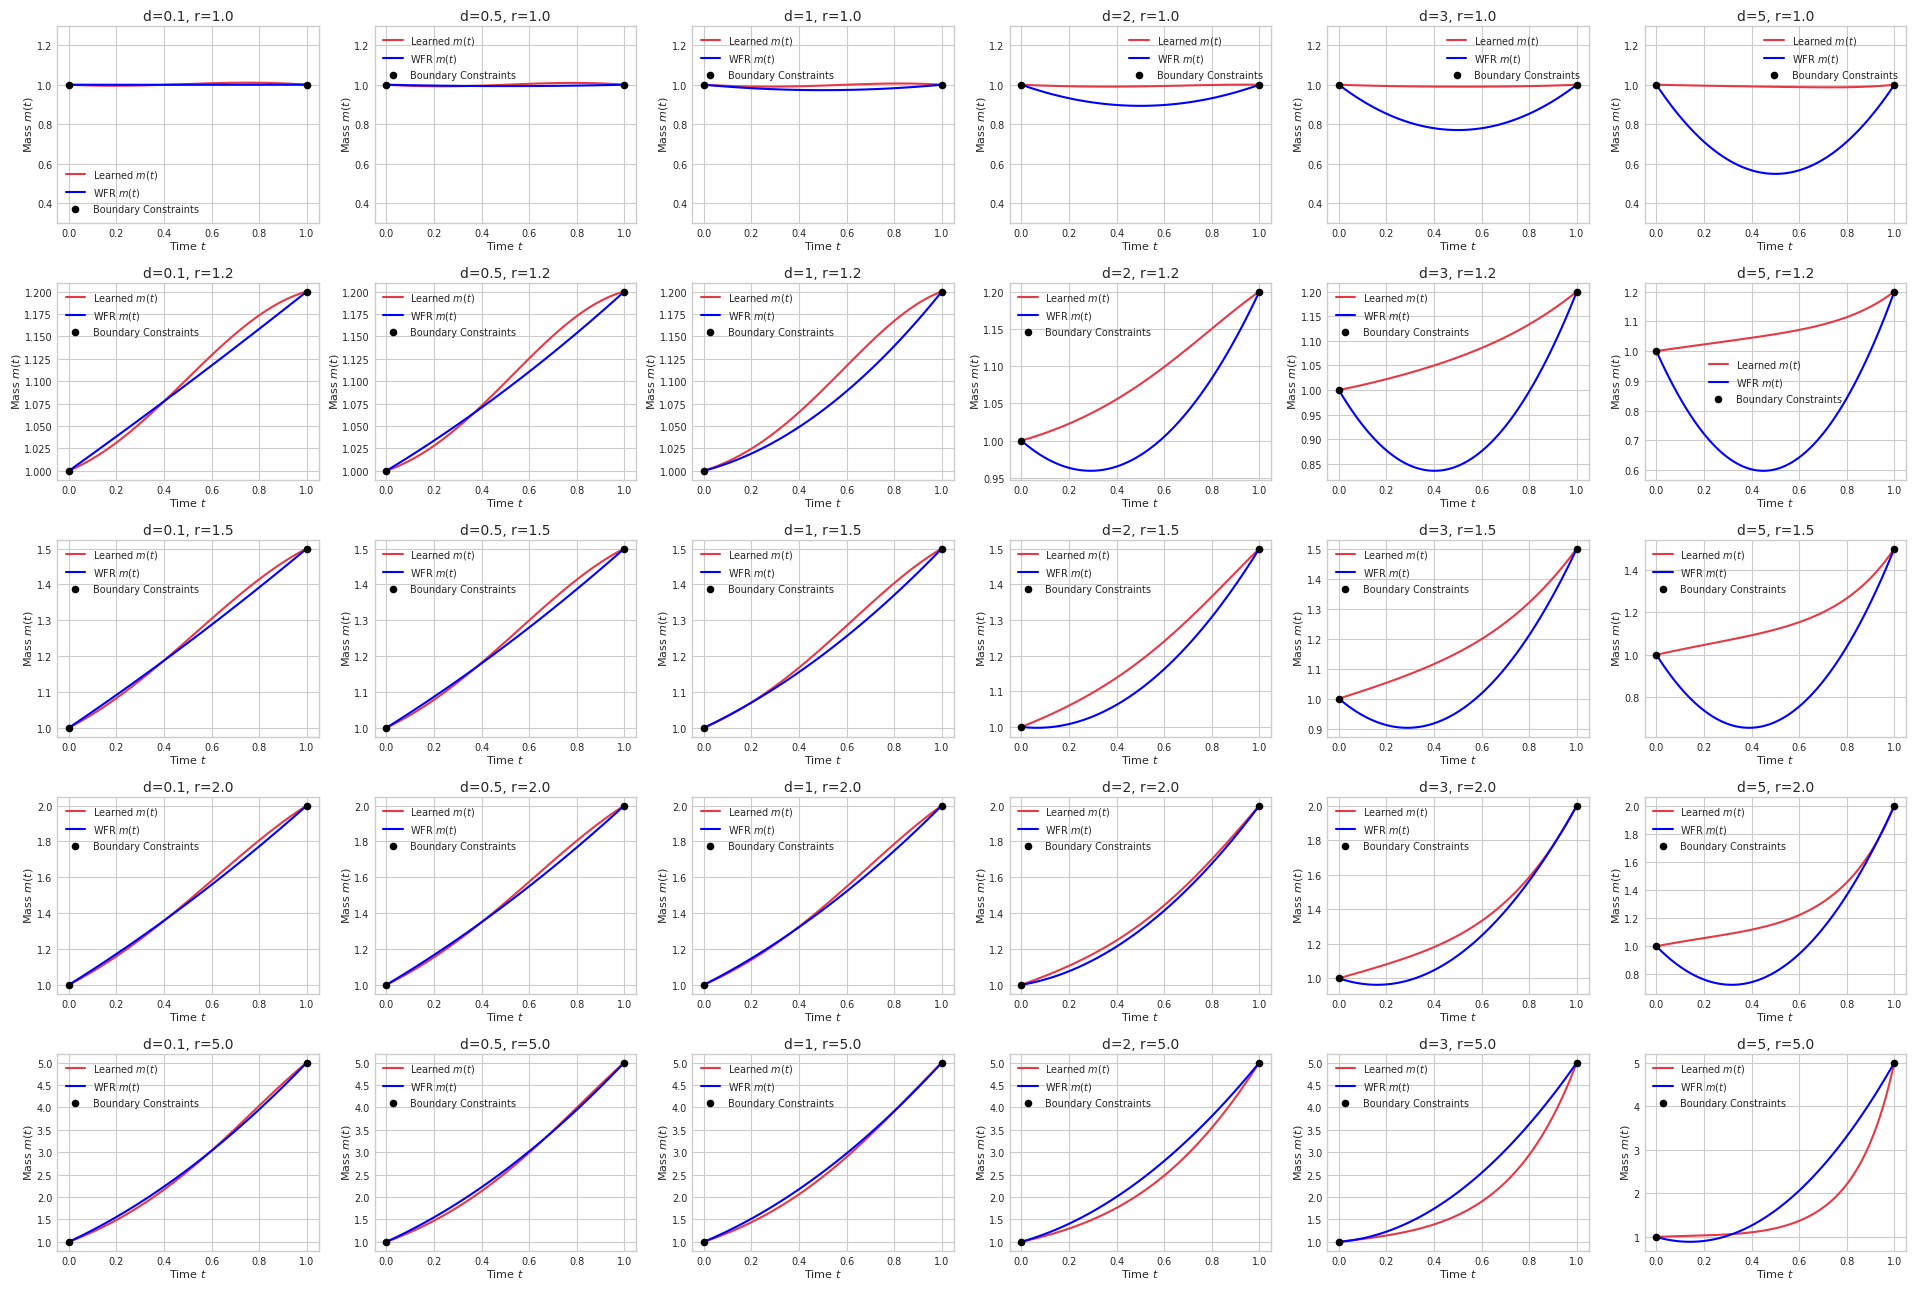

In [89]:
d_list = [0.1, 0.5, 1, 2, 3, 5]
r_list = [1.0, 1.2, 1.5, 2.0, 5.0]
visualize_path_grid(path_model, d_list, r_list, device='cuda', delta=delta, save='only_growth.png')


## Only-death path

In [90]:
torch.manual_seed(42)

delta = 1.5
# Define the experiment-specific mass-change penalty.
def Psi(g):


    safe_g_pos = -(torch.relu(-g) + 1e-8)
    cost_growth = 1.0 + safe_g_pos - safe_g_pos * torch.log(-safe_g_pos)

    cost_death = 10000*(g ** 2)+1


    return delta*torch.where(g < 0, cost_growth, cost_death)


device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
path_model = train_ruot_pinn(RUOT_TrajectoryNet, Psi, epochs=3000, device=device, batch_size=4096, lr=0.001)


🚀 Starting PINN Training on cuda (Batch=4096)
Epoch [   1/3000] | Action Loss: 3.242862e+05 | LR: 1.00e-03


Epoch [ 500/3000] | Action Loss: 2.450720e+05 | LR: 9.34e-04
Epoch [1000/3000] | Action Loss: 2.376294e+05 | LR: 7.52e-04
Epoch [1500/3000] | Action Loss: 2.365345e+05 | LR: 5.05e-04
Epoch [2000/3000] | Action Loss: 2.369251e+05 | LR: 2.57e-04
Epoch [2500/3000] | Action Loss: 2.368453e+05 | LR: 7.63e-05
Epoch [3000/3000] | Action Loss: 2.368871e+05 | LR: 1.00e-05
✅ Training Complete! The neural surrogate now approximates the optimal trajectory.


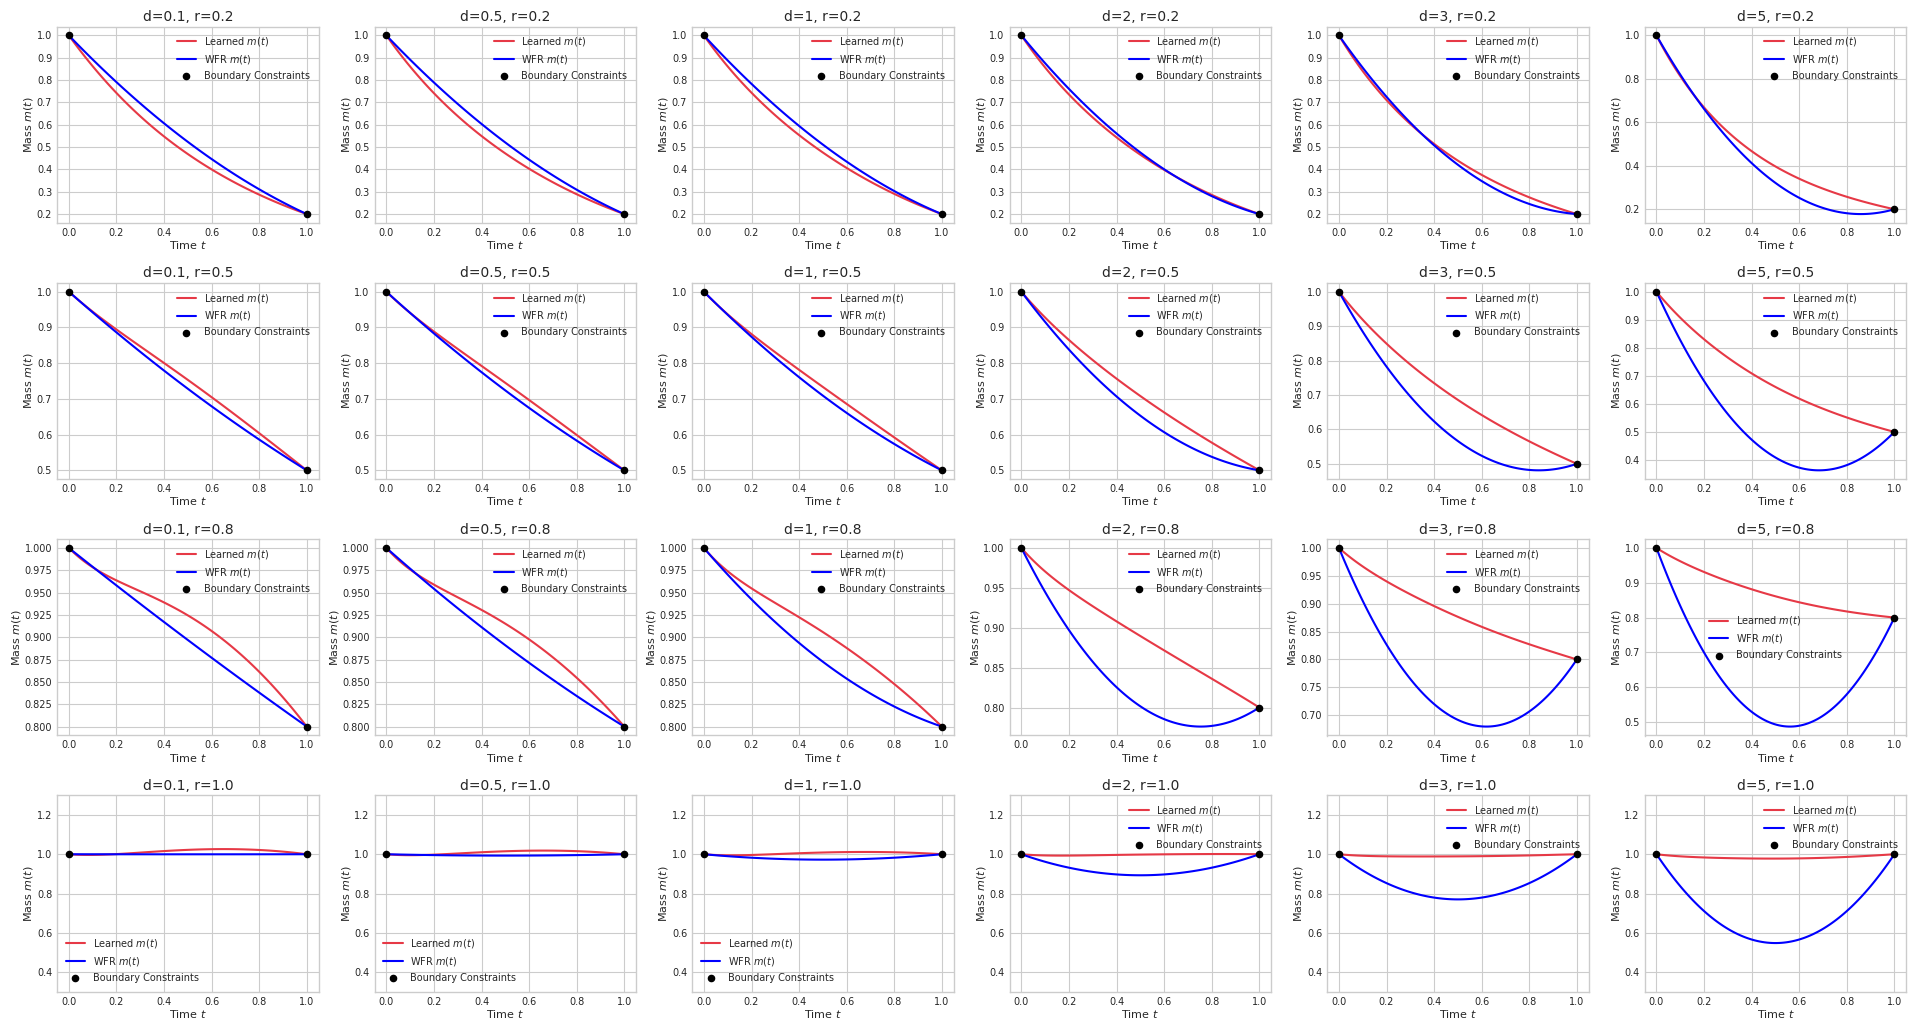

In [91]:
d_list = [0.1, 0.5, 1, 2, 3, 5]
r_list = [0.2, 0.5, 0.8, 1.0]
visualize_path_grid(path_model, d_list, r_list, device='cuda', delta=delta, save='only_death.png')
